Q33.	Perform preprocessing on a house-pricing dataset: inspect missing values, impute or remove them as appropriate, and encode categorical features.

In [1]:
import pandas as pd

df = pd.read_csv('house_raw.csv')
print(df.isnull().sum())

df = df.dropna(subset=['Price'])
df['Area'] = df['Area'].fillna(df['Area'].mean())
df['Bedrooms'] = df['Bedrooms'].fillna(df['Bedrooms'].median())
df['Location'] = df['Location'].fillna(df['Location'].mode()[0])
df['Furnished'] = df['Furnished'].fillna(df['Furnished'].mode()[0])

df['Furnished'] = df['Furnished'].map({'Yes': 1, 'No': 0})
df = pd.get_dummies(df, columns=['Location'], dtype=int)
print(df)

Area         1
Bedrooms     1
Location     1
Furnished    1
Price        1
dtype: int64
     Area  Bedrooms  Furnished  Price  Location_City  Location_Suburb
0  1000.0       2.0          1   50.0              0                1
1  1200.0       3.0          0   75.0              1                0
2  1362.5       3.0          1   80.0              1                0
4  1800.0       4.0          1  110.0              1                0
5   900.0       2.0          0   45.0              1                0
6  2000.0       5.0          1  140.0              1                0
7  1100.0       3.0          1   60.0              0                1
8  1600.0       3.0          0   95.0              1                0
9  1300.0       3.0          1   65.0              0                1


Q34.	Analyze relationships among numerical variables using a correlation matrix and heatmap. Identify and briefly interpret one strong relationship.

                Exercise_Hours  Calories    Weight       Age
Exercise_Hours        1.000000  0.999565 -0.994538 -0.187451
Calories              0.999565  1.000000 -0.994756 -0.195082
Weight               -0.994538 -0.994756  1.000000  0.192708
Age                  -0.187451 -0.195082  0.192708  1.000000


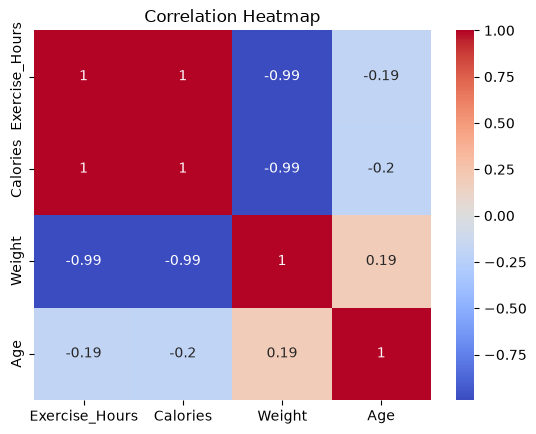

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('fitness.csv')
corr = df.corr()
print(corr)

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Q35.	Import a dataset, measure skewness, and apply a suitable log or Box-Cox transformation where its assumptions are satisfied. Compare the distributions before and after transformation.

2.3871036215632033
1.149911811732947


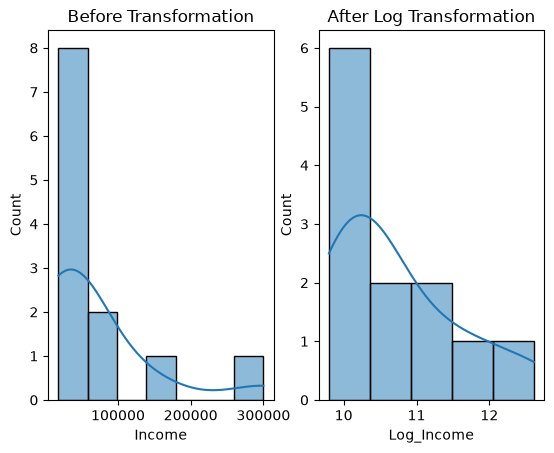

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('income_skew.csv')
print(df['Income'].skew())

df['Log_Income'] = np.log1p(df['Income'])
print(df['Log_Income'].skew())

plt.subplot(1, 2, 1)
sns.histplot(df['Income'], kde=True)
plt.title('Before Transformation')

plt.subplot(1, 2, 2)
sns.histplot(df['Log_Income'], kde=True)
plt.title('After Log Transformation')
plt.show()

Q36.	Create scatter plots with regression lines and density plots. Explain one pattern observed in the visualizations.

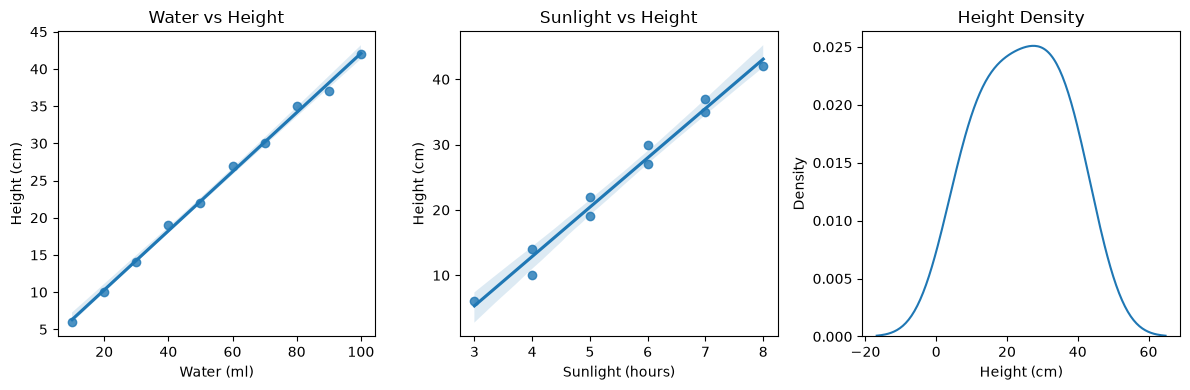

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('plants.csv')
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.regplot(x='Water', y='Height', data=df)
plt.xlabel('Water (ml)')
plt.ylabel('Height (cm)')
plt.title('Water vs Height')

plt.subplot(1, 3, 2)
sns.regplot(x='Sunlight', y='Height', data=df)
plt.xlabel('Sunlight (hours)')
plt.ylabel('Height (cm)')
plt.title('Sunlight vs Height')

plt.subplot(1, 3, 3)
sns.kdeplot(df['Height'])
plt.xlabel('Height (cm)')
plt.ylabel('Density')
plt.title('Height Density')

plt.tight_layout()
plt.show()